# 01 EDA: UCI HAR
Set `UCI_ROOT` if the data is not at `../data/uci/UCI HAR Dataset`.

In [1]:
import os, sys, yaml, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "../src")
from data_loader import load_uci, split_val
from preprocess import fit_norm
cfg = yaml.safe_load(open("../config/config.yaml"))
ROOT = os.environ.get("UCI_ROOT", "../data/uci/UCI HAR Dataset")
FIG = "../reports/figures"; os.makedirs(FIG, exist_ok=True)
d = load_uci(ROOT); acts = cfg["activities"]
{k: v["X_raw"].shape for k, v in d.items()}

{'train': (7352, 128, 9), 'test': (2947, 128, 9)}

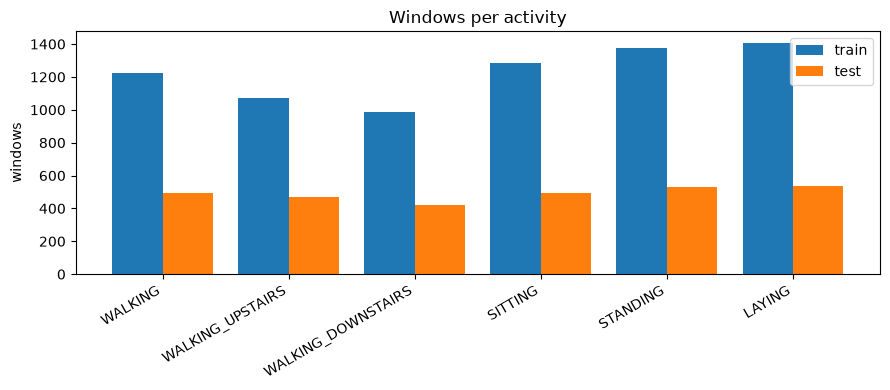

In [2]:
fig, ax = plt.subplots(figsize=(9, 4)); w = 0.4
for i, s in enumerate(["train", "test"]):
    ax.bar(np.arange(6) + (i - .5) * w, np.bincount(d[s]["y"], minlength=6), w, label=s)
ax.set_xticks(range(6), acts, rotation=30, ha="right"); ax.set_ylabel("windows"); ax.legend()
ax.set_title("Windows per activity"); fig.tight_layout(); fig.savefig(f"{FIG}/windows_per_activity.png", dpi=120)

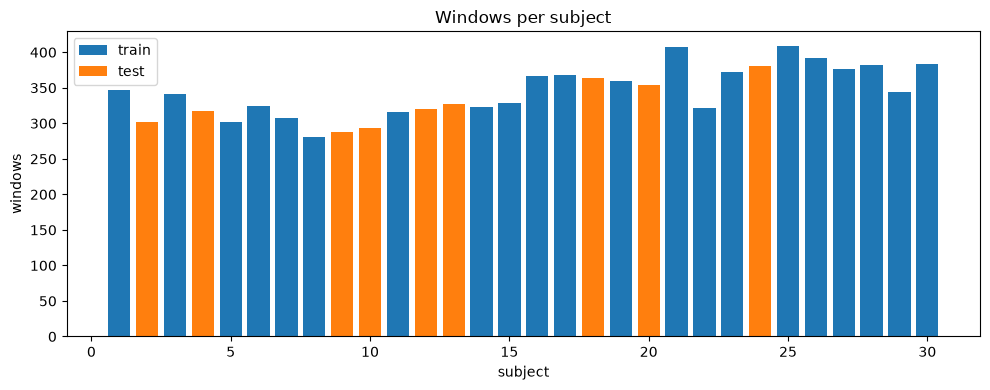

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for s in ["train", "test"]:
    u, n = np.unique(d[s]["subject"], return_counts=True); ax.bar(u, n, label=s)
ax.set_xlabel("subject"); ax.set_ylabel("windows"); ax.legend(); ax.set_title("Windows per subject")
fig.tight_layout(); fig.savefig(f"{FIG}/windows_per_subject.png", dpi=120)

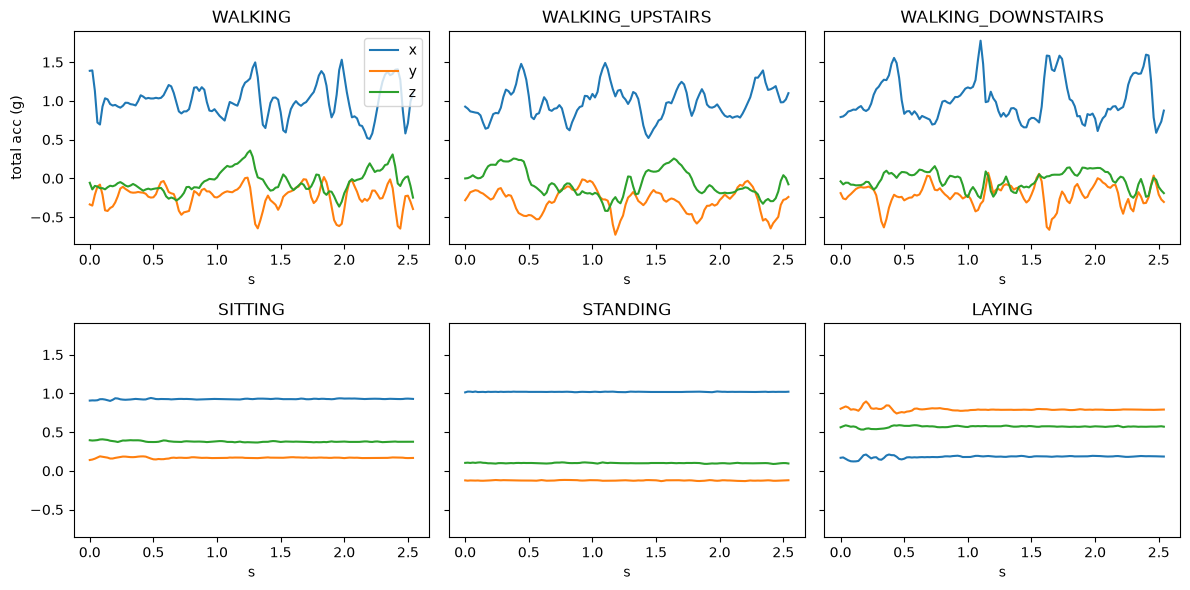

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharey=True); t = np.arange(128) / 50
for a, ax in enumerate(axs.flat):
    w = d["train"]["X_raw"][np.argmax(d["train"]["y"] == a)]
    for j, n in enumerate("xyz"): ax.plot(t, w[:, 6 + j], label=n)
    ax.set_title(acts[a]); ax.set_xlabel("s")
axs[0, 0].set_ylabel("total acc (g)"); axs[0, 0].legend()
fig.tight_layout(); fig.savefig(f"{FIG}/example_windows.png", dpi=120)

In [5]:
overlap = set(d["train"]["subject"]) & set(d["test"]["subject"])
assert not overlap, overlap
print("No subject in both train and test.")

No subject in both train and test.


In [6]:
tr, va = split_val(d["train"], cfg["split"]["uci_val"])
assert not set(tr["subject"]) & set(va["subject"])
print("train", tr["X_raw"].shape, "val", va["X_raw"].shape, "val subjects", sorted(set(va["subject"])))
mean, std = fit_norm(tr["X_raw"], "../" + cfg["norm_stats"])   # train subjects only
print("mean", mean.round(3)); print("std", std.round(3))

train (6281, 128, 9) val (1071, 128, 9) val subjects [np.int64(3), np.int64(22), np.int64(25)]
mean [-0.001 -0.    -0.    -0.002 -0.    -0.     0.805  0.027  0.072]
std [0.197 0.122 0.109 0.403 0.4   0.263 0.415 0.388 0.366]
